### Research question: Which players over- and underperform their non-penalty expected goals (npxG), and is playing time related to the result?

The analysis uses FBref data from the first 20 matchweeks of the 2025/26 Premier League season, downloaded in January 2026. I **rank** players within their **club and position group**, so that I can answer a sporting director’s question: “which of my players finish better or worse than their chances suggest, compared with teammates in the same position?”. I also calculate the correlation between playing time and non-penalty goals per 90 minus npxG per 90 (npG/90 − npxG/90).

In [1]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt

In [2]:
con = sqlite3.connect("PLStats.db")

In [3]:
stats = pd.read_excel("data/PremierLeagueStats.xlsx", sheet_name="Player Standard Stats", decimal=',')
stats = stats.rename(columns={"G-PK/90":"np_goals_per90", "npxG/90":"npxg_per90", "Minutes":"minutes", "Squad ID":"squad_id", "Player Fullname":"player_name", "Player ID":"player_id", "npxG":"npxg"})
stats.to_sql(name="stats", con=con, if_exists="replace", index=False)

positions = pd.read_excel("data/PremierLeagueStats.xlsx", sheet_name="Player Positions")
positions = positions.rename(columns={"Player ID":"player_id", "Player Position":"position"})
positions.to_sql(name="positions", con=con, if_exists="replace", index=True, index_label="pos_id")

squad = pd.read_excel("data/PremierLeagueStats.xlsx", sheet_name="Squad Standard Stats", decimal=',')
squad = squad.rename(columns={"Squad ID":"squad_id", "Squad":"squad_name"})
squad = squad[["squad_id", "squad_name"]]
squad.to_sql(name="squad", con=con, if_exists="replace", index=False);


In [4]:
pd.read_sql_query("SELECT * FROM stats", con=con)

,player_id,Player Name,Player Surname,Nation Code,squad_id,Age,Born,Matches Played,Starts,minutes,...,Assists/90,G+A/90,np_goals_per90,G+A-PK/90,xG/90,xAG/90,xG+xAG/90,npxg_per90,npxG+xAG/90,player_name
0,1,Brenden,Aaronson,USA,11,25-081,2000,20,14,1245,...,0.22,0.51,0.29,0.51,0.21,0.20,0.41,0.21,0.41,Brenden Aaronson
1,2,Zach,Abbott,ENG,16,19-243,2006,1,0,45,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,Zach Abbott
2,3,Joshua,Acheampong,ENG,7,19-251,2006,8,6,470,...,0.00,0.19,0.19,0.19,0.12,0.01,0.13,0.12,0.13,Joshua Acheampong
3,4,Tyler,Adams,USA,3,26-331,1999,15,15,1195,...,0.08,0.23,0.15,0.23,0.03,0.01,0.04,0.03,0.04,Tyler Adams
4,5,Tosin,Adarabioyo,ENG,7,28-109,1997,10,6,651,...,0.00,0.00,0.00,0.00,0.01,0.09,0.11,0.01,0.11,Tosin Adarabioyo
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
488,489,Leny,Yoro,FRA,14,20-059,2005,21,12,1141,...,0.00,0.00,0.00,0.00,0.05,0.00,0.06,0.05,0.06,Leny Yoro
489,490,Oleksandr,Zinchenko,UKR,16,29-027,1996,5,4,353,...,0.00,0.00,0.00,0.00,0.02,0.13,0.15,0.02,0.15,Oleksandr Zinchenko
490,491,Joshua,Zirkzee,NED,14,24-234,2001,14,4,490,...,0.18,0.55,0.37,0.55,0.36,0.17,0.52,0.36,0.52,Joshua Zirkzee
491,492,Martín,Zubimendi,ESP,1,26-343,1999,21,20,1769,...,0.05,0.20,0.15,0.20,0.10,0.05,0.15,0.10,0.15,Martín Zubimendi


In [5]:
pd.read_sql_query("SELECT * FROM positions", con=con)

,pos_id,player_id,position
0,0,1,FW
1,1,1,MF
2,2,2,DF
3,3,3,DF
4,4,4,MF
...,...,...,...
612,612,490,DF
613,613,491,FW
614,614,491,MF
615,615,492,MF


In [6]:
pars = {"min_minutes":300, "excluded_position":"GK", "min_npxg":1, "min_same_pos_squad":3}

There are 92 players (among those above the minimum-minutes threshold, excluding goalkeepers) with two positions assigned by FBref. I keep only their primary position, assuming (although it is not proven) that FBref lists the main position first. I checked this against several Liverpool players, including Jeremie Frimpong, who for this part of the season played mainly as a winger, which is why his first listed position is 'FW'.

In [7]:
pd.read_sql_query("""SELECT COUNT(positions.player_id) - COUNT(DISTINCT positions.player_id)
                        FROM stats
                        INNER JOIN positions
                        ON stats.player_id = positions.player_id
                        WHERE minutes > :min_minutes AND positions.position <> :excluded_position
                        """, con=con, params=pars)

,COUNT(positions.player_id) - COUNT(DISTINCT positions.player_id)
0,92


As the scatter plot below shows, most of the extreme `g_xg_diff` values come with low npxG. I wanted a filter that leaves only players with enough shooting chances to draw conclusions from. The higher the npxG threshold, the smaller the noise, but the fewer players remain. A threshold of npxG ≥ 1 strikes a balance: it removes players with very few chances, yet leaves 33 club + position groups of three or more players that a coach can compare (including defender groups, which are excluded later). It is a judgement call based on data from 20 matchweeks.

In [8]:
pd.read_sql_query("""WITH players AS (
                                      SELECT stats.player_id as player_id, player_name, squad_id, positions.position AS position, 
                                      positions.pos_id, RANK() OVER (PARTITION BY positions.player_id ORDER BY pos_id) AS prim_pos, minutes, npxg
                                      FROM stats
                                      INNER JOIN positions
                                      ON stats.player_id = positions.player_id),
                    players_grouped AS (
                                      SELECT COUNT(player_id) AS num_players, position, squad_id FROM players
                                      WHERE minutes > :min_minutes AND position <> :excluded_position AND prim_pos = 1 AND npxg >= :min_npxg
                                      GROUP BY squad_id, position),
                    to_be_counted AS (SELECT position, squad_id FROM players_grouped
                    WHERE num_players >= :min_same_pos_squad)
                    SELECT position, COUNT(*) AS number_of_groups FROM to_be_counted GROUP BY position""", con=con, params=pars)

,position,number_of_groups
0,DF,4
1,FW,17
2,MF,12


This is the `outfield_players` DataFrame, used for the scatter plot. It contains every player above the minimum-minutes threshold, excluding goalkeepers, with only their primary position kept (as explained above). The npxG threshold and the exclusion of defenders are deliberately not applied here, as the plot shows why both are necessary.

In [9]:
outfield_players = pd.read_sql_query("""WITH players AS (
                                                  SELECT stats.player_id AS player_id, player_name, 
                                                  np_goals_per90 - npxg_per90 AS g_xg_diff, 
                                                  squad_id, positions.position AS position, positions.pos_id, 
                                                  RANK() OVER (PARTITION BY positions.player_id ORDER BY pos_id) AS prim_pos, 
                                                  minutes, npxg
                                                  FROM stats
                                                  INNER JOIN positions
                                                  ON stats.player_id = positions.player_id),
                                    players_filtered AS (
                                                      SELECT player_name, g_xg_diff, position, squad_id,
                                                      minutes, prim_pos, npxg
                                                      FROM players
                                                      WHERE minutes > :min_minutes AND position <> :excluded_position AND prim_pos = 1)
                                    SELECT player_name, g_xg_diff, position, squad_id,
                                    npxg, minutes
                                    FROM players_filtered
                                    ORDER BY npxg DESC""", con=con, params=pars)

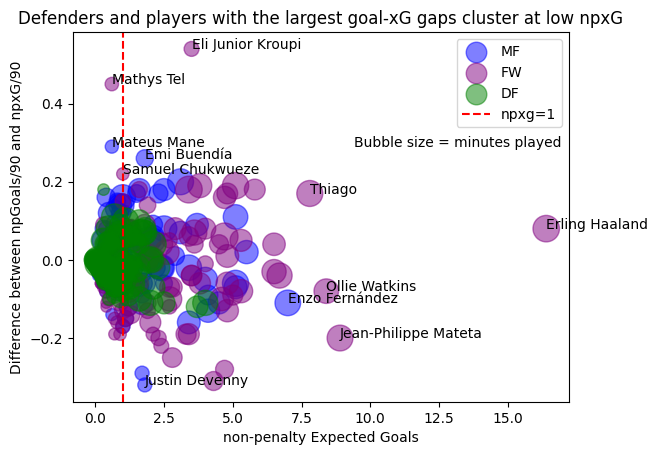

In [10]:
plt.scatter(x=outfield_players[outfield_players["position"] == "MF"]["npxg"], y=outfield_players[outfield_players["position"] == "MF"]["g_xg_diff"], c="blue", alpha=0.5, label="MF", 
            s=outfield_players[outfield_players["position"] == "MF"]["minutes"]/5)
plt.scatter(x=outfield_players[outfield_players["position"] == "FW"]["npxg"], y=outfield_players[outfield_players["position"] == "FW"]["g_xg_diff"], c="purple", alpha=0.5, label="FW", 
            s=outfield_players[outfield_players["position"] == "FW"]["minutes"]/5)
plt.scatter(x=outfield_players[outfield_players["position"] == "DF"]["npxg"], y=outfield_players[outfield_players["position"] == "DF"]["g_xg_diff"], c="green", alpha=0.5, label="DF", 
            s=outfield_players[outfield_players["position"] == "DF"]["minutes"]/5)
plt.text(x=9.4, y=0.29, s="Bubble size = minutes played")
plt.axvline(x=1, color='red', linestyle='--', label='npxg=1')
for _, row in outfield_players.iterrows():
    if (row["g_xg_diff"] > 0.2) | (row["g_xg_diff"] < -0.31) | (row["npxg"] >= 7):
        plt.annotate(row["player_name"], (row["npxg"], row["g_xg_diff"]), )
plt.title("Defenders and players with the largest goal-xG gaps cluster at low npxG")
plt.xlabel("non-penalty Expected Goals")
plt.ylabel("Difference between npGoals/90 and npxG/90")
plt.legend();

The filters have their limits, as the example below shows. Eli Junior Kroupi **passes every filter**, yet his overperformance may reflect a hot streak rather than proof of finishing skill. His per-90 overperformance is almost **seven times** Haaland's, even though Haaland, one of the most prolific strikers in recent seasons, has nearly **five times his npxG**, which makes Haaland's figure far **more reliable**. Haaland will be excluded from the final ranking only because Manchester City do not have three forwards who pass every filter.

In [11]:
outfield_players[outfield_players["player_name"].isin(["Eli Junior Kroupi", "Erling Haaland"])]

,player_name,g_xg_diff,position,squad_id,npxg,minutes
0,Erling Haaland,0.08,FW,13,16.4,1821
41,Eli Junior Kroupi,0.54,FW,3,3.5,576


This is the final ranking, with all filters applied. Players are ranked by `g_xg_diff` within each *club + position group*, and only groups with at least three players are kept. **Defenders** are also excluded: as the scatter plot above shows, most of them **fall below an npxG of 1**, which leaves only four defender groups after the threshold, too few to compare. **Shooting** is also not a **defender's primary role**, so a finishing metric says little about them.

In [12]:
club_pos_rank = pd.read_sql_query("""WITH players AS (
                                      SELECT stats.player_id AS player_id, player_name, np_goals_per90 - npxg_per90 AS g_xg_diff, 
                                      stats.squad_id as squad_id, positions.position AS position, positions.pos_id,
                                      RANK() OVER (PARTITION BY positions.player_id ORDER BY pos_id) AS prim_pos, minutes, npxg, squad.squad_name AS squad_name
                                      FROM stats
                                      INNER JOIN positions ON stats.player_id = positions.player_id
                                      INNER JOIN squad ON squad.squad_id = stats.squad_id),
                          players_filtered AS (
                                          SELECT player_name, g_xg_diff, position, squad_id, 
                                          COUNT(player_id) OVER (PARTITION BY squad_id, position) AS same_pos_squad, 
                                          minutes, prim_pos, npxg, squad_name
                                          FROM players
                                          WHERE minutes > :min_minutes AND position <> :excluded_position AND position <> 'DF' AND prim_pos = 1 AND npxg >= :min_npxg)
                    SELECT player_name, g_xg_diff, position,
                    RANK() OVER (PARTITION BY squad_id, position ORDER BY g_xg_diff DESC) AS squad_rank, npxg, minutes, squad_name
                    FROM players_filtered
                    WHERE same_pos_squad >= :min_same_pos_squad""", con=con, params=pars)

The number of players in the final ranking, by position.

In [13]:
club_pos_rank.groupby(by="position").agg({"player_name":"count"})

,player_name
position,
FW,71
MF,46


The fifteen biggest underperformers in the final ranking (`club_pos_rank`), by *npG/90 − npxG/90*.

In [14]:
club_pos_rank[["player_name", "g_xg_diff", "npxg", "squad_name"]].sort_values(by="g_xg_diff", ascending=True).head(15)

,player_name,g_xg_diff,npxg,squad_name
48,Justin Devenny,-0.32,1.8,Crystal Palace
17,David Brooks,-0.31,4.3,Bournemouth
43,Andrey Santos,-0.29,1.7,Chelsea
52,Beto,-0.28,4.7,Everton
90,Anthony Gordon,-0.25,2.8,Newcastle Utd
40,Liam Delap,-0.22,2.4,Chelsea
39,Estêvão Willian,-0.20,2.3,Chelsea
116,Jhon Arias,-0.19,3.3,Wolves
3,Gabriel Martinelli,-0.19,2.1,Arsenal
97,Igor Jesus,-0.19,3.4,Nottingham Forest


The fifteen biggest overperformers in the final ranking (`club_pos_rank`), by *npG/90 − npxG/90*.

In [15]:
club_pos_rank[["player_name", "g_xg_diff", "npxg", "squad_name"]].sort_values(by="g_xg_diff", ascending=False).head(15)

,player_name,g_xg_diff,npxg,squad_name
13,Eli Junior Kroupi,0.54,3.5,Bournemouth
57,Samuel Chukwueze,0.22,1.0,Fulham
91,Bruno Guimarães,0.20,3.1,Newcastle Utd
14,Antoine Semenyo,0.19,5.1,Bournemouth
58,Harry Wilson,0.19,3.8,Fulham
32,Zian Flemming,0.18,1.6,Burnley
8,Morgan Rogers,0.18,3.4,Aston Villa
53,Kiernan Dewsbury-Hall,0.18,1.6,Everton
68,Hugo Ekitike,0.18,5.8,Liverpool
25,Danny Welbeck,0.17,4.8,Brighton


The top-ranked player in each *club + position group* by *npG/90 − npxG/90* (tied players share first place).

In [16]:
club_pos_rank[club_pos_rank["squad_rank"] == 1][["player_name", "g_xg_diff", "npxg", "squad_name", "position"]]

,player_name,g_xg_diff,npxg,squad_name,position
0,Leandro Trossard,0.08,4.0,Arsenal,FW
4,Eberechi Eze,0.17,2.3,Arsenal,MF
8,Morgan Rogers,0.18,3.4,Aston Villa,FW
13,Eli Junior Kroupi,0.54,3.5,Bournemouth,FW
18,Justin Kluivert,-0.02,2.2,Bournemouth,MF
19,Marcus Tavernier,-0.02,3.4,Bournemouth,MF
21,Thiago,0.17,7.8,Brentford,FW
25,Danny Welbeck,0.17,4.8,Brighton,FW
28,Georginio Rutter,0.00,1.9,Brighton,MF
32,Zian Flemming,0.18,1.6,Burnley,FW


The correlation between `g_xg_diff` and `minutes`, calculated for all 372 players above the minimum-minutes threshold, across all positions. Excluding **goalkeepers changes r by less than 0.01**, so there is no need to complicate the query. The correlation is not calculated on `club_pos_rank`, because npxG depends on minutes played: filtering by npxG would introduce **selection bias**. With **r ≈ 0.10**, the correlation is very weak, meaning playing time has almost no relationship with whether a player over- or underperforms his xG.

In [17]:
pd.read_sql_query("SELECT COUNT(*) FROM stats WHERE minutes > :min_minutes", con=con, params=pars)

,COUNT(*)
0,372


In [18]:
pd.read_sql_query(sql = """WITH avg_min_g AS (
                                              SELECT np_goals_per90 - npxg_per90 AS g_xg_diff, minutes,
                                              AVG(np_goals_per90 - npxg_per90) OVER () AS avg_diff,
                                              AVG(minutes) OVER () AS avg_min 
                                              FROM stats
                                              WHERE minutes > :min_minutes), 
                                pwr_cov AS (
                                        SELECT POWER(g_xg_diff - avg_diff, 2) AS pwr_diff_xg,
                                        POWER(minutes - avg_min, 2) AS pwr_diff_min,
                                        (g_xg_diff - avg_diff)*(minutes - avg_min) AS cov
                                        FROM avg_min_g), 
                                elements AS (
                                         SELECT 1.0/(COUNT(*)-1)*SUM(pwr_diff_xg) AS var_xg, 
                                         1.0/(COUNT(*)-1)*SUM(pwr_diff_min) AS var_min,
                                         1.0/(COUNT(*)-1)*SUM(cov) AS cov FROM pwr_cov)
                            SELECT cov/(SQRT(var_min)*SQRT(var_xg)) AS corr_pearson 
                            FROM elements""", con = con, params=pars)

,corr_pearson
0,0.103409


Checked against the pandas `.corr()` method: the results match.

In [19]:
stats["g_xg_diff"] = stats["np_goals_per90"] - stats["npxg_per90"]
stats[stats["minutes"] > pars.get("min_minutes")][["minutes","g_xg_diff"]].corr(method="pearson")

,minutes,g_xg_diff
minutes,1.000000,0.103409
g_xg_diff,0.103409,1.000000


### Conclusions
The biggest **overperformers** are Eli Junior Kroupi (+0.54, npxG 3.5) and Samuel Chukwueze (+0.22, npxG 1.0), while the biggest **underperformers** are Justin Devenny (−0.32, npxG 1.8) and David Brooks (−0.31, npxG 4.3). However, **half a season is not enough** to draw firm conclusions from these numbers alone, as extreme values are not necessarily the effect of a player’s skill (for instance, Samuel Chukwueze sits exactly at the npxG threshold). **Defenders** were deliberately **excluded**: only four defender groups had at least three players above the npxG ≥ 1 threshold, as most defenders fall below it (see the scatter plot), so over half a season this finishing metric says little about them. The **correlation** between minutes played and `g_xg_diff` is **very weak** (r ≈ 0.10, based on all 372 players with more than 300 minutes), which means **playing time has almost no relationship with whether a player finishes above or below his npxG**.

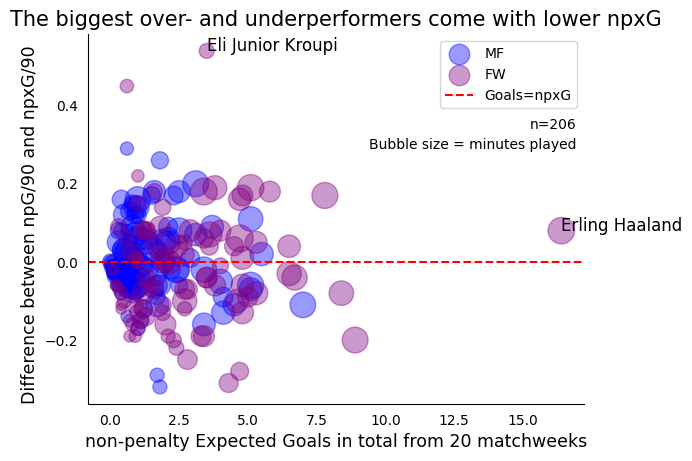

In [91]:
plt.scatter(x=outfield_players[outfield_players["position"] == "MF"]["npxg"], y=outfield_players[outfield_players["position"] == "MF"]["g_xg_diff"], c="blue", alpha=0.4, label="MF", 
            s=outfield_players[outfield_players["position"] == "MF"]["minutes"]/5)
plt.scatter(x=outfield_players[outfield_players["position"] == "FW"]["npxg"], y=outfield_players[outfield_players["position"] == "FW"]["g_xg_diff"], c="purple", alpha=0.4, label="FW", 
            s=outfield_players[outfield_players["position"] == "FW"]["minutes"]/5)
#plt.scatter(x=outfield_players[outfield_players["position"] == "DF"]["npxg"], y=outfield_players[outfield_players["position"] == "DF"]["g_xg_diff"], c="green", alpha=0.4, label="DF", 
#           s=outfield_players[outfield_players["position"] == "DF"]["minutes"]/5)
plt.text(x=9.4, y=0.29, s="Bubble size = minutes played")
plt.text(x=15.25, y=0.34, s="n=206")
plt.axhline(y=0, color='red', linestyle='--', label='Goals=npxG')
for _, row in outfield_players.iterrows():
    if (row["player_name"] == "Eli Junior Kroupi") | (row["player_name"] == "Erling Haaland"):
        plt.annotate(row["player_name"], (row["npxg"], row["g_xg_diff"]), size = 12)
plt.title("The biggest over- and underperformers come with lower npxG", loc='center', size=15)
plt.xlabel("non-penalty Expected Goals in total from 20 matchweeks", size = 12.5)
plt.ylabel("Difference between npG/90 and npxG/90", loc ='bottom', size = 12.5)
plt.legend()
plt.tick_params(axis='x', which='both', bottom=False,
                top=False, labelbottom=True)
plt.tick_params(axis='y', which='both', right=False,
                left=False, labelleft=True)
for pos in ['right', 'top']:
    plt.gca().spines[pos].set_visible(False)
plt.savefig(fname="linkedin_post",dpi=1500, bbox_inches='tight');

In [92]:
outfield_players[outfield_players["position"].isin(["MF", "FW"])]["player_name"].count()

np.int64(206)

In [93]:
con.close()